In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import nibabel as nib

import sys
sys.path.append("/home/agustin/phd/synthesis/utils")

import util_freesurfer_segmentation as ufs



from cornucopia import (
    RandomSmoothLabelMap,
    RandomErodeLabelTransform,
    RandomDilateLabelTransform,
    RandomSmoothMorphoLabelTransform,
    SmoothBernoulliTransform,
    BernoulliDiskTransform,
    SmoothBernoulliDiskTransform,
    random,
)

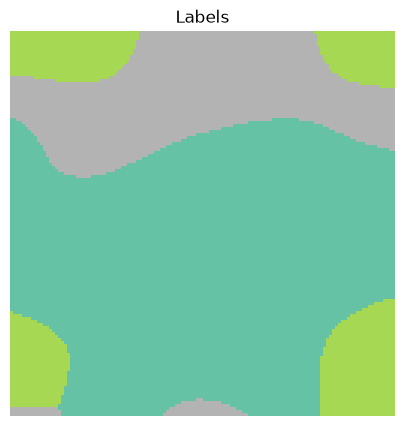

In [20]:
xform = RandomSmoothLabelMap(nb_classes=random.Fixed(3))

lab = xform(torch.empty([]).expand([1, 128, 128]))

plt.figure(figsize=(5, 5))
plt.imshow(lab.squeeze(), cmap='Set2', interpolation='nearest')
plt.axis('off')
plt.title('Labels')
plt.show()

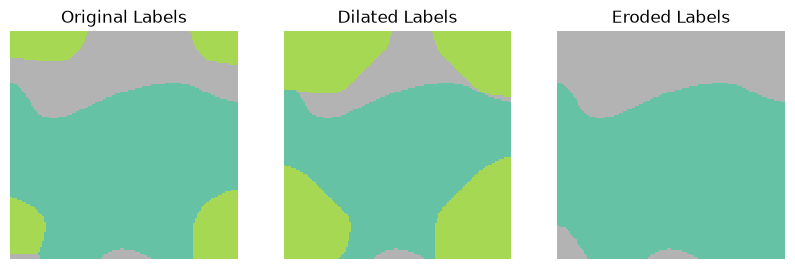

In [29]:
vmax = lab.max()
dlab = RandomDilateLabelTransform(labels=[1], radius=40)(lab)
elab = RandomErodeLabelTransform(labels=[1], radius=40)(lab)

plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.imshow(lab.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Original Labels')
plt.subplot(1, 3, 2)
plt.imshow(dlab.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Dilated Labels')
plt.subplot(1, 3, 3)
plt.imshow(elab.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Eroded Labels')
plt.show()

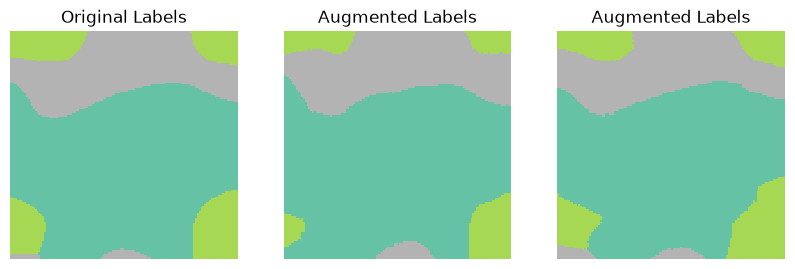

In [37]:
vmax = lab.max()
xform = RandomSmoothMorphoLabelTransform(min_radius=-32, max_radius=32, shape=16)
lab1 = xform(lab)
lab2 = xform(lab)

plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.imshow(lab.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Original Labels')
plt.subplot(1, 3, 2)
plt.imshow(lab1.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Augmented Labels')
plt.subplot(1, 3, 3)
plt.imshow(lab2.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Augmented Labels')
plt.show()

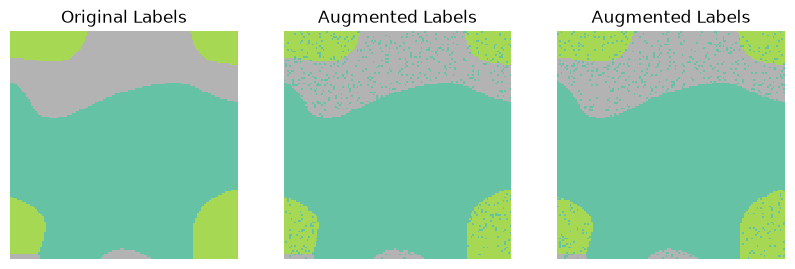

In [39]:
vmax = lab.max()
xform = SmoothBernoulliTransform()
lab1 = xform(lab)
lab2 = xform(lab)

plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.imshow(lab.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Original Labels')
plt.subplot(1, 3, 2)
plt.imshow(lab1.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Augmented Labels')
plt.subplot(1, 3, 3)
plt.imshow(lab2.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax)
plt.axis('off')
plt.title('Augmented Labels')
plt.show()

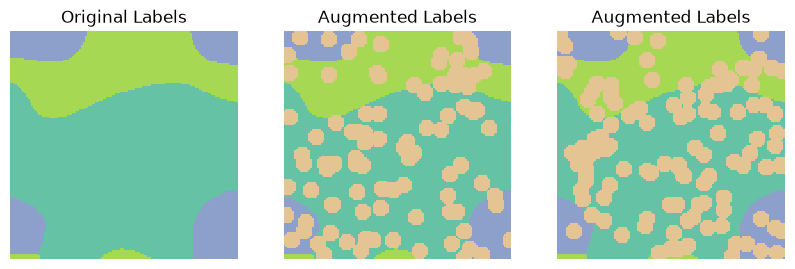

In [40]:
vmax = lab.max()
xform = BernoulliDiskTransform(radius=5, value=vmax+1, method='l2')
lab1 = xform(lab)
lab2 = xform(lab)

plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.imshow(lab.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax+2)
plt.axis('off')
plt.title('Original Labels')
plt.subplot(1, 3, 2)
plt.imshow(lab1.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax+2)
plt.axis('off')
plt.title('Augmented Labels')
plt.subplot(1, 3, 3)
plt.imshow(lab2.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax+2)
plt.axis('off')
plt.title('Augmented Labels')
plt.show()

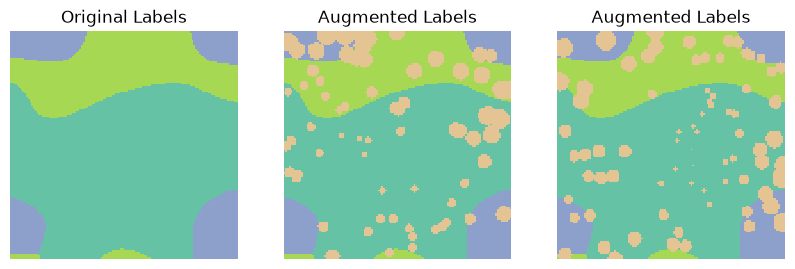

In [41]:
vmax = lab.max()
xform = SmoothBernoulliDiskTransform(radius=15, value=vmax+1, method='l2')
lab1 = xform(lab)
lab2 = xform(lab)

plt.figure(figsize=(10, 10))
plt.subplot(1, 3, 1)
plt.imshow(lab.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax+2)
plt.axis('off')
plt.title('Original Labels')
plt.subplot(1, 3, 2)
plt.imshow(lab1.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax+2)
plt.axis('off')
plt.title('Augmented Labels')
plt.subplot(1, 3, 3)
plt.imshow(lab2.squeeze(), cmap='Set2', interpolation='nearest', vmin=0, vmax=vmax+2)
plt.axis('off')
plt.title('Augmented Labels')
plt.show()

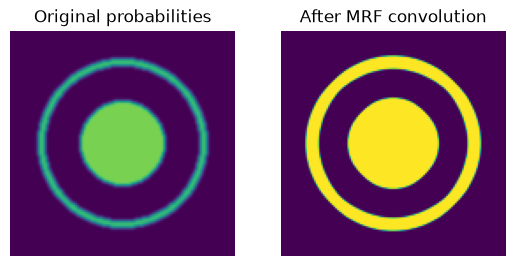

In [42]:
# Soft labels with MRF

from cornucopia.utils.mrf import mrf_conv
from cornucopia.utils.conv import smooth2d
from cornucopia.utils.py import meshgrid_ij
import torch
import matplotlib.pyplot as plt

# Generate ring probability
shape = [128, 128]
radius = torch.stack(meshgrid_ij(*[torch.arange(s).float() for s in shape]), -1)
radius -= (torch.as_tensor(shape).float() - 1) / 2
radius = radius.square().sum(-1).sqrt()

prob = torch.zeros_like(radius)
prob[radius < 48] = 0.7
prob[radius < 44] = 0
prob[radius < 24] = 0.8
prob = smooth2d(prob, fwhm=[2]*2)
prob = prob[None]  # channel dimension

log_mrf = torch.as_tensor([
    [+1.0, -0.5],    # log p(1|1), log p(1|0)
    [-0.5, +0.5],    # log p(0|1), log p(0|0)
], dtype=torch.float32).T
log_likelihood = (prob-0.5)*1

dilated_prob = mrf_conv(prob, log_mrf, log_likelihood, max_iter=10, tol=0)


plt.subplot(1, 2, 1)
plt.title('Original probabilities')
plt.imshow(prob.squeeze(), vmin=0, vmax=1)
plt.clim(0, 1)
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title('After MRF convolution')
plt.imshow(dilated_prob.squeeze(), vmin=0, vmax=1)
plt.clim(0, 1)
plt.axis('off')
plt.show()

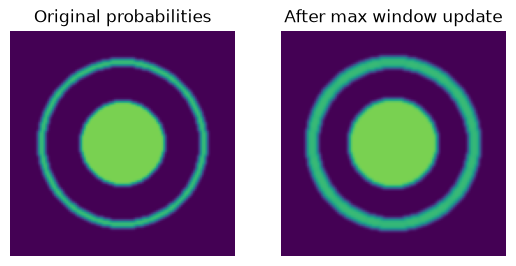

In [43]:
# Soft labels with MRF

from cornucopia.utils.conv import smooth2d
from cornucopia.utils.pool import pool2d
from cornucopia.utils.py import meshgrid_ij
import torch
import matplotlib.pyplot as plt

# Generate ring probability
shape = [128, 128]
radius = torch.stack(meshgrid_ij(*[torch.arange(s).float() for s in shape]), -1)
radius -= (torch.as_tensor(shape).float() - 1) / 2
radius = radius.square().sum(-1).sqrt()

prob = torch.zeros_like(radius)
prob[radius < 48] = 0.7
prob[radius < 44] = 0
prob[radius < 24] = 0.8
prob = smooth2d(prob, fwhm=[2]*2)
prob = prob[None]  # channel dimension

mrf = [
    [0.80, 0.20],   # p(1|1) + p(0|1) = 1
    [0.40, 0.60],   # p(1|0) + p(0|0) = 1
]
log_mrf = torch.tensor(mrf, dtype=torch.float32).log().T

log_mrf = torch.as_tensor([
    [+1.0, -0.5],    # log p(1|1), log p(1|0)
    [-0.5, +0.5],    # log p(0|1), log p(0|0)
], dtype=torch.float32).T

dilated_prob = prob.clone()
for _ in range(3):
    dilated_prob.mul_(pool2d(
        dilated_prob,
        reduction='max',
        kernel_size=3,
        stride=1,
        padding='same'
    )).sqrt_()


plt.subplot(1, 2, 1)
plt.title('Original probabilities')
plt.imshow(prob.squeeze(), vmin=0, vmax=1)
plt.clim(0, 1)
plt.axis('off')
plt.subplot(1, 2, 2)
plt.title('After max window update')
plt.imshow(dilated_prob.squeeze(), vmin=0, vmax=1)
plt.clim(0, 1)
plt.axis('off')
plt.show()